In [12]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import warnings
warnings.filterwarnings('ignore')

from pdm_model import Net, SimpleNet
from cProfile import label
from multiprocessing import process
from numpy import number
from sklearn.decomposition import PCA
from sympy import reduced
import test
%matplotlib widget
# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cuda


In [13]:
class QANumberDataset(Dataset):
    """
    Dataset for the adding problem task.

    Args:
        seq_len: Length of the sequence (default: 20)
        num_samples: Number of samples in the dataset
    """

    def __init__(self, seq_len=20, num_samples=1000):

        np.random.seed(42)  # For reproducibility

        self.seq_len = seq_len
        self.num_samples = num_samples

        max_k = 15
        min_k = 10
        self.max_k = max_k
        self.min_k = min_k
        numeration = np.random.randint(min_k, max_k+1, (num_samples, ))
        # print('k-ary:', numeration[:20])
        numeration_onehot = np.eye(max_k-min_k+1)[numeration-min_k].reshape((num_samples, 1, max_k-min_k+1)).repeat(seq_len*2-1, 1)
        # numeration = numeration.reshape(-1,1)

        numbers = np.random.randint(0, max_k, (num_samples, seq_len))
        operators = np.random.randint(0, 2, (num_samples, seq_len-1))

        self.number_projection = np.eye(max_k, max_k+2)
        projection_size = self.number_projection.shape[-1]
        # self.operator_projection = np.random.uniform(0,1,(2,projection_size))
        self.operator_projection = torch.zeros((2, projection_size))
        self.operator_projection[0,max_k] = 1
        self.operator_projection[1,max_k+1] = 1

        self.data = np.zeros((num_samples, seq_len*2-1, projection_size))
        current_value = numbers[:, 0] % numeration
        self.data[:,0] = self.number_projection[current_value]
        # print(current_value[:20])
        for i in range(seq_len-1):
            multiplier = operators[:,i] * 2 - 1
            self.data[:,2*i+1] = self.operator_projection[operators[:,i]]
            # print(self.operator_projection[operators[:20,i]].argmax(-1).cpu().numpy())
            num = numbers[:,i+1]
            self.data[:,2*i+2] = self.number_projection[num]
            # print(num[:20])
            next_value = (current_value + multiplier * num) % numeration
            current_value = next_value
        self.data = torch.FloatTensor(np.concatenate([numeration_onehot, self.data], -1))
        self.targets = torch.FloatTensor(current_value).long()
        # print('results:', self.targets[:20])
        self.input_size = self.data.shape[-1]
        self.output_size = max_k

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        return self.data[idx], self.targets[idx]

# Create datasets
train_dataset = QANumberDataset(seq_len=2, num_samples=50000)
test_dataset = QANumberDataset(seq_len=2, num_samples=50000)

print(f"Training dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

# Show example


min_k = train_dataset.min_k
max_k = train_dataset.max_k
n_numeration = max_k-min_k+1
for i in range(10):
    idx = np.random.randint(len(train_dataset))
    sample_input, sample_target = train_dataset[idx]
    # print(f"\nExample input shape: {sample_input.shape}")
    numeration = sample_input[0,:n_numeration].argmax(-1)+min_k
    example_input = sample_input[:,n_numeration:].argmax(-1)
    print('(', end=' ')
    for j in range(len(example_input)):
        if example_input[j] < max_k:
            print(example_input[j].item(), end=' ')
        elif example_input[j] == max_k:
            print('-', end=' ')
        elif example_input[j] == max_k+1:
            print('+', end=' ')
    print(f' ) % {numeration} = {sample_target}')

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

Training dataset size: 50000
Test dataset size: 50000
( 10 - 0  ) % 11 = 10
( 14 + 12  ) % 15 = 11
( 6 + 3  ) % 11 = 9
( 5 - 11  ) % 11 = 5
( 1 - 12  ) % 12 = 1
( 11 + 14  ) % 13 = 12
( 6 - 7  ) % 11 = 10
( 0 + 5  ) % 10 = 5
( 3 + 1  ) % 11 = 4
( 3 + 1  ) % 10 = 4


In [14]:

device='cuda:0'
batch_size = 64
hidden_size = 64
input_size = train_dataset.input_size  # [number, indicator]
output_size = train_dataset.output_size  # regression output
simple_net = SimpleNet(ob_size=input_size, num_h=hidden_size, act_size=output_size).to(device)
net = Net(ob_size=input_size, num_h=hidden_size, act_size=output_size, entropy_loss=True).to(device)
net_path = './model/k-base_computation/ei_net.pth'
simple_net_path = './model/k-base_computation/simple_net.pth'
net.load_state_dict(torch.load(net_path))
simple_net.load_state_dict(torch.load(simple_net_path))

<All keys matched successfully>

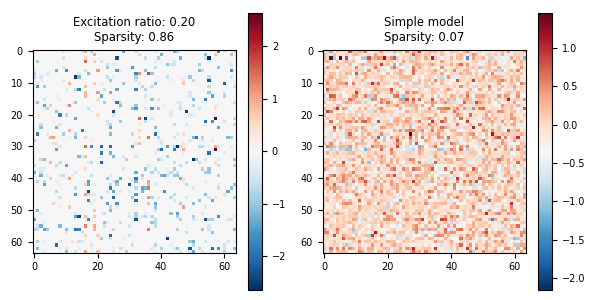

In [19]:
weight = net.get_actual_weight().detach().cpu().numpy()
fig, ax = plt.subplots(1,2,figsize=(6,3))
limit = 0.9*max(np.max(weight), np.max(-weight))
im = ax[0].imshow(weight, cmap='RdBu_r', vmin=-limit, vmax=limit)
sparsity = 1 - np.mean(np.abs(weight)>0.1*np.std(np.abs(weight)))
eimask = net.lstm.eimask_logit.detach().cpu().numpy()
# mask = F.gumbel_softmax(net.lstm.eimask_logit, tau=0.1, hard=False, dim=-1).detach().cpu().numpy()
exc_ratio = np.mean(eimask[:, 0] > eimask[:, 1])
ax[0].set_title(f'Excitation ratio: {exc_ratio:.2f}\nSparsity: {sparsity:.2f}')
plt.colorbar(im, ax=ax[0])

weight_simple = simple_net.get_actual_weight().detach().cpu().numpy()
im = ax[1].imshow(weight_simple, cmap='RdBu_r')
sparsity_simple = 1 - np.mean(np.abs(weight_simple)>0.1*np.std(np.abs(weight_simple)))
ax[1].set_title(f'Simple model\nSparsity: {sparsity_simple:.2f}')
plt.colorbar(im, ax=ax[1])
plt.tight_layout()

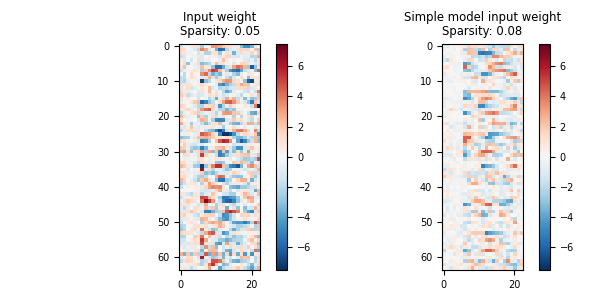

In [20]:
weight = net.lstm.input_layer.weight.detach().cpu().numpy()
simple_weight = simple_net.lstm.input_layer.weight.detach().cpu().numpy()
fig, ax = plt.subplots(1,2,figsize=(6,3))
limit = 0.9*max(np.max(weight), np.max(-weight))
im = ax[0].imshow(weight, cmap='RdBu_r', vmin=-limit, vmax=limit)
sparsity = 1 - np.mean(np.abs(weight)>0.1*np.std(np.abs(weight)))
ax[0].set_title(f'Input weight\nSparsity: {sparsity:.2f}')
plt.colorbar(im, ax=ax[0])
sparsity_simple = 1 - np.mean(np.abs(simple_weight)>0.1*np.std(np.abs(simple_weight)))
im = ax[1].imshow(simple_weight, cmap='RdBu_r', vmin=-limit, vmax=limit)
ax[1].set_title(f'Simple model input weight\nSparsity: {sparsity_simple:.2f}')
plt.colorbar(im, ax=ax[1])
plt.tight_layout()
plt.show()

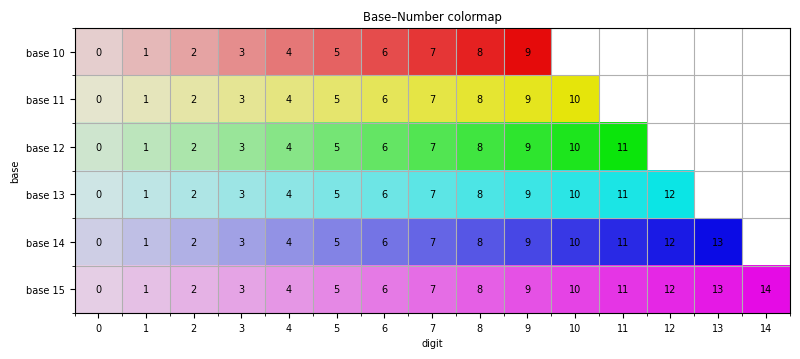

In [15]:
import numpy as np
import colorsys
from matplotlib.colors import ListedColormap, BoundaryNorm

def make_base_number_cmap(
    base_to_max_digit: dict,
    saturation: float = 0.9,
    min_value: float = 0.1,   # 最浅
    max_value: float = 0.95,   # 最深（同一色系中最“纯”）
    name: str = "base_number_cmap",
):
    """
    为 (base, number) 构建一个离散 colormap（每个进制一组色系，数字由浅到深）。

    参数
    ----
    saturation : float
        HSV 的饱和度，建议 0.8~0.95。
    min_value, max_value : float
        HSV 的 value（亮度）范围；0→黑，1→最亮。这里数字从 0→max_digit
        对应从 value=max_value(浅) 到 value=min_value(深)。
    name : str
        colormap 的名字。

    返回
    ----
    cmap : ListedColormap
    norm : BoundaryNorm
    base_offsets : dict
        每个 base 的起始索引（用于把 (base, number) 编码成一个整数标签）
    total_classes : int
        总的颜色类别数（= sum(max_digit+1)）
    """
    bases = sorted(base_to_max_digit.keys())
    B = len(bases)

    hues = np.linspace(0.0, 1.0, B, endpoint=False)

    colors = []
    base_offsets = {}
    idx = 0

    for i, b in enumerate(bases):
        base_offsets[b] = idx
        m = int(base_to_max_digit[b])

        for n in range(m + 1):
            # n=0 最浅，n=m 最深（同一色系由浅到深）
            t = 0.0 if m == 0 else (n / m)
            s = min_value + (max_value - min_value) * t
            h = float(hues[i])
            v = float(saturation)
            r, g, b_rgb = colorsys.hsv_to_rgb(h, s, v)
            colors.append((r, g, b_rgb))
            idx += 1

    cmap = ListedColormap(colors, name=name)
    N = len(colors)
    # 离散类别的规范化：每个整数标签对应一个颜色格
    norm = BoundaryNorm(boundaries=np.arange(N + 1) - 0.5, ncolors=N)
    return cmap, norm, base_offsets, N


def encode_labels(base_ids: np.ndarray, numbers: np.ndarray, base_offsets: dict) -> np.ndarray:
    """
    把 (base, number) 编码成一个整数标签，用于传给 colormap。

    要求 base_ids 与 numbers 同形状（1D）。
    """
    assert base_ids.shape == numbers.shape
    labels = np.empty_like(base_ids, dtype=int)
    for b, offset in base_offsets.items():
        mask = (base_ids == b)
        # 这里假定 numbers[mask] ∈ [0, max_digit[b]]
        labels[mask] = offset + numbers[mask]
    return labels

def visualize_base_number_cmap(
    base_to_max_digit: dict,
    cmap: ListedColormap,
    norm: BoundaryNorm,
    base_offsets: dict,
    title: str | None = "Base–Number colormap",
    show_text: bool = True,
    figsize=(8, 0.6),
    xtick_step: int = 1,
):
    """
    以 n 行（每行一个 base）、从左到右为数字 0..max_digit 的方式，展示整个 cmap。
    """
    bases = sorted(base_to_max_digit.keys())
    rows = len(bases)
    max_cols = max(m + 1 for m in base_to_max_digit.values())

    # 构造一个 [rows, max_cols] 的标签网格；无效格子填 NaN 以隐藏
    grid = np.full((rows, max_cols), np.nan, dtype=float)
    for i, b in enumerate(bases):
        m = base_to_max_digit[b]
        for n in range(m + 1):
            grid[i, n] = base_offsets[b] + n

    # 画图
    fig_h = max(2.0, rows * figsize[1])  # 行多时自动增高
    fig, ax = plt.subplots(figsize=(figsize[0], fig_h))
    im = ax.imshow(grid, cmap=cmap, norm=norm, aspect="auto", interpolation="nearest")

    # 轴与刻度
    ax.set_yticks(np.arange(rows))
    ax.set_yticklabels([f"base {b}" for b in bases])
    ax.set_xticks(np.arange(0, max_cols, xtick_step))
    ax.set_xticklabels(np.arange(0, max_cols, xtick_step))

    # 网格线（使用 minor ticks，不指定颜色，以默认样式绘制）
    ax.set_xticks(np.arange(-0.5, max_cols, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, rows, 1), minor=True)
    ax.grid(which="minor")

    # 可选：在有效格子上标注数字
    if show_text:
        for i, b in enumerate(bases):
            m = base_to_max_digit[b]
            for n in range(m + 1):
                ax.text(n, i, str(n), ha="center", va="center")

    if title:
        ax.set_title(title)
    ax.set_xlabel("digit")
    ax.set_ylabel("base")
    plt.tight_layout()
    return fig, ax
min_k = train_dataset.min_k
max_k = train_dataset.max_k
base_to_max_digit = {k: k - 1 for k in range(min_k, max_k + 1)}
cmap, norm, base_offsets, total_classes = make_base_number_cmap(base_to_max_digit)
fig, ax = visualize_base_number_cmap(
    base_to_max_digit, cmap, norm, base_offsets)

In [16]:
import numpy as np


def plot_PCA_2d(h_all, label_all):
    digit1 = h_all[:,0].reshape(-1, hidden_size)
    color1 = label_all[:, :, 0].reshape(-1)
    op = h_all[:,1].reshape(-1, hidden_size)
    color_op = label_all[:, :, 1].reshape(-1)
    digit2 = h_all[:,2].reshape(-1, hidden_size)
    color2 = label_all[:, :, 2].reshape(-1)
    # 2D PCA visualization
    fig, ax = plt.subplots(1,3,figsize=(15,4))
    pca1 = PCA(n_components=2)
    reduced_1 = pca1.fit_transform(digit1)
    ax[0].scatter(reduced_1[:,0], reduced_1[:,1], cmap=cmap, norm=norm, c=color1)
    ax[0].set_title('PCA of first number representation')
    pca2 = PCA(n_components=2)
    reduced_2 = pca2.fit_transform(digit2)
    ax[1].scatter(reduced_2[:,0], reduced_2[:,1], cmap=cmap, norm=norm, c=color2)
    ax[1].set_title('PCA of second number representation')
    pca_op = PCA(n_components=2)
    reduced_op = pca_op.fit_transform(op)
    print(color_op)
    ax[2].scatter(reduced_op[:,0], reduced_op[:,1], c=color_op, cmap='viridis')
    ax[2].set_title('PCA of operator representation')
    ax[2].legend()
    plt.tight_layout()
    plt.show()
    plt.close()

def plot_PCA_3d(h_all, label_all):
    digit1 = h_all[:,0].reshape(-1, hidden_size)
    color1 = label_all[:, :, 0].reshape(-1)
    op = h_all[:,1].reshape(-1, hidden_size)
    color_op = label_all[:, :, 1].reshape(-1)
    digit2 = h_all[:,2].reshape(-1, hidden_size)
    color2 = label_all[:, :, 2].reshape(-1)

    # 3D PCA visualization
    fig = plt.figure(figsize=(18,5))
    axes = [fig.add_subplot(1,3,i+1, projection='3d') for i in range(3)]

    # 1) 第一位数字
    pca1 = PCA(n_components=3)
    reduced_1 = pca1.fit_transform(digit1)  # shape: [N, 3]
    axes[0].scatter(reduced_1[:,0], reduced_1[:,1], reduced_1[:,2],
                    c=color1, cmap=cmap, norm=norm, s=8, alpha=0.9, depthshade=False)

    axes[0].set_title(f'PCA(3) first number (var={pca1.explained_variance_ratio_[:3].sum():.2f})')
    axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2'); axes[0].set_zlabel('PC3')

    # 2) 第二位数字
    pca2 = PCA(n_components=3)
    reduced_2 = pca2.fit_transform(digit2)
    axes[1].scatter(reduced_2[:,0], reduced_2[:,1], reduced_2[:,2],
                    c=color2, cmap=cmap, norm=norm, s=8, alpha=0.9, depthshade=False)
    axes[1].set_title(f'PCA(3) second number (var={pca2.explained_variance_ratio_[:3].sum():.2f})')
    axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2'); axes[1].set_zlabel('PC3')

    # 3) 运算符（假设 color_op ∈ {0,1}；若是 {-1,1}，先做 op_vals = (color_op+1)//2）
    pca_op = PCA(n_components=3)
    reduced_op = pca_op.fit_transform(op)
    op_vals = color_op
    axes[2].scatter(reduced_op[:,0], reduced_op[:,1], reduced_op[:,2],
                    c=op_vals, cmap='viridis', s=8, alpha=0.9, depthshade=False)
    axes[2].set_title('PCA(3) operator')
    axes[2].set_xlabel('PC1'); axes[2].set_ylabel('PC2'); axes[2].set_zlabel('PC3')

    for ax in axes:
        ax.view_init(elev=20, azim=35)

    plt.tight_layout()
    plt.show()

def decode_labels_to_base_digit(labels, base_offsets: dict, base_to_max_digit: dict):
    labels = np.asarray(labels)
    base_out  = np.full_like(labels, -1, dtype=int)
    digit_out = np.full_like(labels, -1, dtype=int)
    for b, off in base_offsets.items():
        m = int(base_to_max_digit[b])
        mask = (labels >= off) & (labels <= off + m)
        digit_out[mask] = labels[mask] - off
        base_out[mask]  = b
    return base_out, digit_out
def plot_centroid_rings_3d_with_samples(
    h_all,                # (n_trials, 3, batch, hidden)
    label_all,            # (n_trials, batch, 3) [num1, op, num2]
    t_idx,                # 0=第一数, 2=第二数
    base_offsets: dict,
    base_to_max_digit: dict,
    cmap, norm,
    per_cluster_max: int | None = 400,   # 每个 (base,digit) 最多取多少样本点
    max_points: int | None = 30000,      # 全局最多保留多少点
    s_pts: float = 6, alpha_pts: float = 0.35,
    lw: float = 2.4, s_centroid: float = 70,
    annotate_digits: bool = False,
    pca_basis: str = "samples",          # "samples" | "centroids" | "both"
    rng: np.random.Generator | None = None,
):
    assert t_idx in (0, 2)
    if rng is None:
        rng = np.random.default_rng(0)

    H = h_all.shape[-1]
    X = h_all[:, t_idx, :, :].reshape(-1, H)                       # (N, H)
    labs = label_all[:, :, 0 if t_idx == 0 else 2].reshape(-1)     # (N,)
    base_vals, digit_vals = decode_labels_to_base_digit(labs, base_offsets, base_to_max_digit)
    assert X.shape[0] == labs.shape[0]

    # 1) 计算每个 (base,digit) 的质心（隐空间 H 维）
    centroids_by_base = {}   # b -> (Nd, H)
    labels_by_base    = {}   # b -> (Nd,)
    bases = sorted(base_to_max_digit.keys())
    for b in bases:
        m = int(base_to_max_digit[b])
        rows, labs_b = [], []
        for d in range(m + 1):
            mask = (base_vals == b) & (digit_vals == d)
            if np.any(mask):
                rows.append(X[mask].mean(axis=0))
                labs_b.append(base_offsets[b] + d)
        if rows:
            centroids_by_base[b] = np.vstack(rows)
            labels_by_base[b]    = np.array(labs_b)

    if not centroids_by_base:
        raise ValueError("当前 t_idx 下没有可用的 (base,digit) 质心。")

    all_centroids = np.vstack(list(centroids_by_base.values()))
    # 2) 统一 PCA 基底
    if pca_basis == "centroids":
        fit_X = all_centroids
    elif pca_basis == "both":
        fit_X = np.vstack([X, all_centroids])
    else:  # "samples"
        fit_X = X
    ncomp = min(3, fit_X.shape[1])
    pca = PCA(n_components=ncomp).fit(fit_X)

    X3_samples    = pca.transform(X)[:, :3]               # (N, 3)
    X3_centroids_by_base = {b: pca.transform(C)[:, :3] for b, C in centroids_by_base.items()}

    # 3) 下采样样本点（可选：每簇上限 + 全局上限）
    idx_keep = []
    if per_cluster_max is not None:
        for b in bases:
            m = int(base_to_max_digit[b])
            for d in range(m + 1):
                mask = np.where((base_vals == b) & (digit_vals == d))[0]
                if mask.size == 0:
                    continue
                if per_cluster_max and mask.size > per_cluster_max:
                    sel = rng.choice(mask, per_cluster_max, replace=False)
                else:
                    sel = mask
                idx_keep.append(sel)
        idx_keep = np.concatenate(idx_keep) if idx_keep else np.array([], dtype=int)
    else:
        idx_keep = np.arange(X3_samples.shape[0])
    if (max_points is not None) and (idx_keep.size > max_points):
        idx_keep = rng.choice(idx_keep, max_points, replace=False)

    # 4) 画图：先样本散点，再叠加质心折线 + 质心点
    fig = plt.figure(figsize=(6, 5))
    ax  = fig.add_subplot(111, projection='3d')

    sc = ax.scatter(X3_samples[idx_keep, 0], X3_samples[idx_keep, 1], X3_samples[idx_keep, 2],
                    c=labs[idx_keep], cmap=cmap, norm=norm,
                    s=s_pts, alpha=alpha_pts, depthshade=False)

    for b in bases:
        if b not in X3_centroids_by_base:
            continue
        X3c = X3_centroids_by_base[b]            # (Nd, 3)，已按 d=0..m 顺序
        labs_b = labels_by_base[b]
        # 质心点（大一些，带白色边）
        ax.scatter(X3c[:,0], X3c[:,1], X3c[:,2],
                   c=labs_b, cmap=cmap, norm=norm,
                   s=s_centroid, depthshade=False, alpha=0.95,
                   edgecolors='white', linewidths=0.7)
        # 质心连线（用该 base 最深色）
        line_color = cmap(norm(base_offsets[b] + base_to_max_digit[b]))
        ax.plot(X3c[:,0], X3c[:,1], X3c[:,2],
                color=line_color, lw=lw, alpha=0.95)

        if annotate_digits:
            for i, lab_val in enumerate(labs_b):
                d = lab_val - base_offsets[b]
                ax.text(X3c[i,0], X3c[i,1], X3c[i,2], str(d), fontsize=8)

    what = "num1" if t_idx == 0 else "num2"
    ax.set_title(f'Centroid rings + samples (t={t_idx}, {what}) — joint PCA(3) on {pca_basis}')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_zlabel('PC3')
    plt.tight_layout(); plt.show()
    return fig, ax

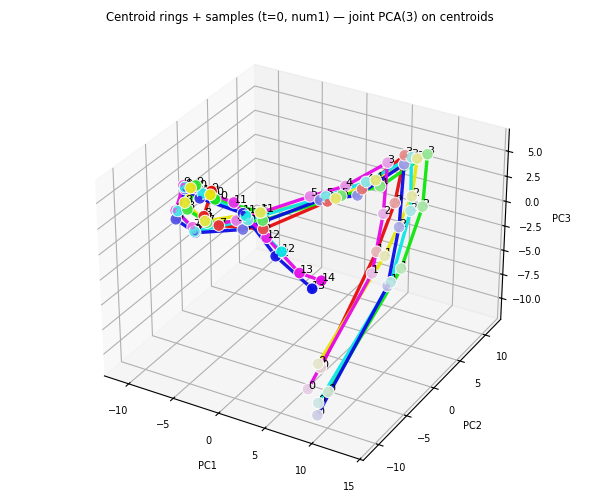

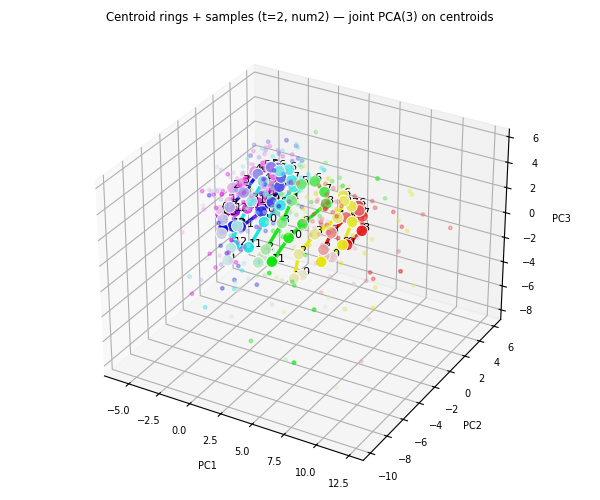

In [17]:

def get_label(batch_inputs, batch_targets, n_numeration):
    numeration = batch_inputs[...,:n_numeration].argmax(-1).detach().cpu().numpy()+min_k  # (seq_len, batch_size)
    base_ids = numeration[0,:]  # numeration
    input_number = batch_inputs[...,n_numeration:].argmax(-1).detach().cpu().numpy()  # (seq_len, batch_size)
    number1 = input_number[0,:]  # first number
    # number2 = input_number[2,:]  # second number
    number2 = batch_targets.detach().cpu().numpy()  # result
    # print('number2:', number2[:20])
    label1 = encode_labels(base_ids, number1, base_offsets)
    label2 = encode_labels(base_ids, number2, base_offsets)
    label_op = input_number[1,:] - max_k
    return label1, label_op, label2
def representation_analysis(model, n_trials=100, batch_size=batch_size, test_dataset=test_dataset):
    model.eval()
    seq_len = 2*train_dataset.seq_len - 1
    min_k = train_dataset.min_k
    max_k = train_dataset.max_k
    n_numeration = max_k-min_k+1
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    h_all = np.zeros((n_trials, seq_len, batch_size, hidden_size))
    label_all = np.zeros((n_trials, batch_size, 3))
    input_layer = model.lstm.input_layer
    # h_all = {k:[[],[],[],[]] for k in range(min_k, max_k+1)}
    loader = iter(test_loader)
    with torch.no_grad():
        for i in range(n_trials):
            batch_inputs, batch_targets = next(loader)
            batch_inputs = batch_inputs.to(device).transpose(0, 1)  # (seq_len, batch_size, input_size)
            processed_inputs = input_layer(batch_inputs).detach().cpu().numpy() # (seq_len, batch_size, hidden_size)
            outputs, _, hidden = model(batch_inputs)
            h = hidden[0].detach().cpu().numpy()  # (seq_len, batch_size, hidden_size)
            h_all[i] = h
            label1, labelop, label2 = get_label(batch_inputs, batch_targets, n_numeration)
            label_all[i,:,0] = label1
            label_all[i,:,1] = labelop
            label_all[i,:,2] = label2



            # numeration = batch_inputs[...,:n_numeration].argmax(-1).detach().cpu().numpy()+min_k  # (seq_len, batch_size)
            # base_ids = numeration[0,:]  # numeration
            # input_number = batch_inputs[...,n_numeration:].argmax(-1).detach().cpu().numpy()  # (seq_len, batch_size)
            # number1 = input_number[0,:]  # first number
            # number2 = input_number[2,:]  # second number
            # for k in range(min_k, max_k+1):
            #     location = np.where(base_ids==k)[0]
            #     if len(location)>0:
            #         label1 = encode_labels(base_ids[location], number1[location], base_offsets)
            #         label2 = encode_labels(base_ids[location], number2[location], base_offsets)
            #         label_op = input_number[1,location] - max_k
            #         h_all[k][0].append(processed_inputs[:,location,:])
            #         h_all[k][1].append(label1)
            #         h_all[k][2].append(label_op)
            #         h_all[k][3].append(label2)

    plot_centroid_rings_3d_with_samples(
        h_all, label_all, t_idx=0,
        base_offsets=base_offsets,
        base_to_max_digit=base_to_max_digit,
        cmap=cmap, norm=norm,
        per_cluster_max=400, max_points=400,
        annotate_digits=True, pca_basis="centroids"  # 或 "both"/"centroids"
    )

    # 叠加 num2 的散点与质心曲线
    plot_centroid_rings_3d_with_samples(
        h_all, label_all, t_idx=2,
        base_offsets=base_offsets,
        base_to_max_digit=base_to_max_digit,
        cmap=cmap, norm=norm,
        per_cluster_max=400, max_points=400,
        annotate_digits=True, pca_basis="centroids"  # 或 "both"/"centroids"
    )


    # fig, ax = plt.subplots(1,n_numeration, figsize=(4*n_numeration,4))
    # for i in range(n_numeration):
    #     k = i + min_k
    #     num_all = np.concatenate(h_all[k][0], axis=1)
    #     digit1 = num_all[0].reshape(-1, hidden_size)
    #     color1 = np.concatenate(h_all[k][1], axis=0).reshape(-1)
    #     op = num_all[1].reshape(-1, hidden_size)
    #     color_op = np.concatenate(h_all[k][2], axis=0).reshape(-1)
    #     digit2 = num_all[2].reshape(-1, hidden_size)
    #     color2 = np.concatenate(h_all[k][3], axis=0).reshape(-1)
    #     pca1 = PCA(n_components=2)
    #     reduced_1 = pca1.fit_transform(digit1)
    #     # reduced_1 = digit1
    #     # print('reduced_1:', reduced_1)
    #     ax[i].scatter(reduced_1[:,0], reduced_1[:,1], cmap=cmap, norm=norm, c=color1)
    #     ax[i].set_title(f'PCA of first number representation (base={k}), len:{len(color1)}')
    # plt.show()



representation_analysis(net, n_trials=100, batch_size=64)


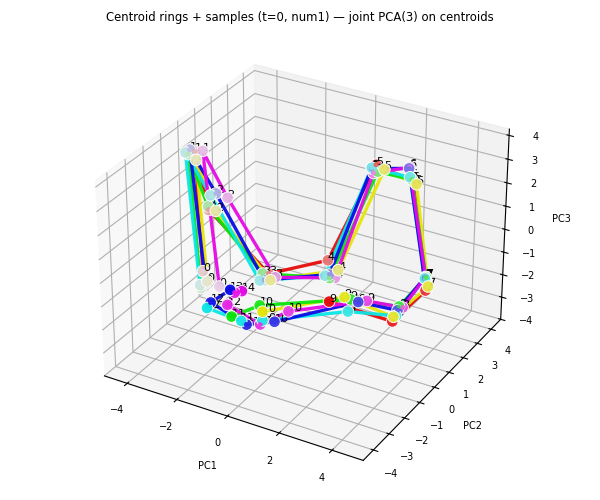

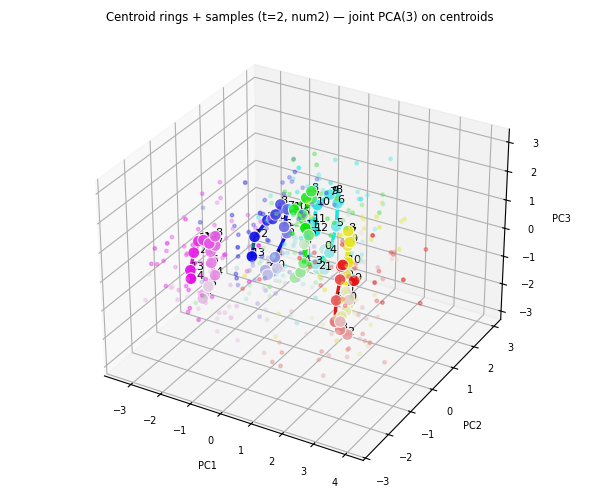

In [18]:
representation_analysis(simple_net, n_trials=100)